In [2]:
# Print the list of columns in the given CSV file
import pandas as pd

csv_path = '../data/processed/power_plant_siting_master_data.csv'

# Read only the header to get column names
columns = pd.read_csv(csv_path, nrows=0).columns.tolist()
print(columns)

['Plant file sequence number', 'Data Year', 'Plant state abbreviation', 'Plant name', 'DOE/EIA ORIS plant or facility code', 'Plant transmission or distribution system owner name', 'Plant transmission or distribution system owner ID', 'Utility name', 'Utility ID', 'Plant-level sector', 'Balancing Authority Name', 'Balancing Authority Code', 'NERC region acronym', 'eGRID subregion acronym', 'eGRID subregion name', 'Plant associated ISO/RTO Territory', 'Plant FIPS state code', 'Plant FIPS county code', 'Plant county name', 'Plant latitude', 'Plant longitude', 'CAPD Program Flag', 'Number of units', 'Number of generators', 'Plant primary fuel', 'Plant primary fuel category', 'Flag indicating if the plant burned or generated any amount of coal', 'Plant capacity factor', 'Plant nameplate capacity (MW)', 'Nonbaseload Factor', 'Biogas/ biomass plant adjustment flag', 'Combined heat and power (CHP) plant adjustment flag', 'CHP plant useful thermal output (MMBtu)', 'CHP plant power to heat rati

In [3]:
# Load main dataset for further inspection and analysis
import pandas as pd

main_csv_path = '../data/processed/power_plant_siting_master_data.csv'
df = pd.read_csv(main_csv_path)

# Print shape and first five rows to visually inspect input
print(f"Data shape: {df.shape}")
df.head()

Data shape: (12612, 167)


/var/folders/4c/rg1h67_11_n4pg2t3_swv4h00000gn/T/ipykernel_1879/2231811643.py:5: DtypeWarning: Columns (33,35,51,52,67,68,97,98,107,122) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(main_csv_path)


,Plant file sequence number,Data Year,Plant state abbreviation,Plant name,DOE/EIA ORIS plant or facility code,Plant transmission or distribution system owner name,Plant transmission or distribution system owner ID,Utility name,Utility ID,Plant-level sector,...,bus_dist_to_nearest_large_generator_km,bus_dist_to_nearest_renewable_plant_km,bus_total_capacity_within_100km_MW,bus_renewable_capacity_within_100km_MW,bus_renewable_share_within_100km,bus_zero_carbon_share_within_100km,plant_bus_distance_km,mean_property_value_3mi,in_lower_48,potable_capacity_mgd_weighted
0,1,2023,AK,Alakanuk,57053,"Alaska Village Elec Coop, Inc",221,"Alaska Village Elec Coop, Inc",221,Electric Utility,...,227.593465,159.902098,2.0,0.0,0.0,0.0,2904.986206,NaN,False,49.141570
1,2,2023,AK,Allison Creek Hydro,58982,"Copper Valley Elec Assn, Inc",4329,"Copper Valley Elec Assn, Inc",4329,Electric Utility,...,227.593465,159.902098,2.0,0.0,0.0,0.0,1968.040225,NaN,False,49.070407
2,3,2023,AK,Ambler,60243,"Alaska Village Elec Coop, Inc",221,"Alaska Village Elec Coop, Inc",221,Electric Utility,...,227.593465,159.902098,2.0,0.0,0.0,0.0,2806.031157,NaN,False,49.254176
3,4,2023,AK,Angoon,7462,"Inside Passage Elec Coop, Inc",18963,"Inside Passage Elec Coop, Inc",18963,Electric Utility,...,227.593465,159.902098,2.0,0.0,0.0,0.0,1216.736924,NaN,False,48.949825
4,5,2023,AK,Aniak,7182,Aniak Light & Power Co Inc,4959,Aniak Light & Power Co Inc,4959,Electric Utility,...,227.593465,159.902098,2.0,0.0,0.0,0.0,2614.820871,NaN,False,49.097531


## Power Plant Multi-Criteria Scoring Pipeline: Explanation & How It Meets the User Request

This coding pipeline implements a robust, transparent, and highly user-editable approach for scoring, ranking, and visualizing US power plant sites across three important categories:
- **Lowest Cost**
- **Lowest Emissions**
- **Highest Reliability**

It follows your exact instructions regarding formulas, weights, and inputs and is carefully engineered to work even if some data is missing or not perfectly formatted. Below is a plain-language breakdown of how the code works:

### 1. **Column Handling & Data Loading**
- The pipeline loads the provided power plant master CSV with its full set of metrics.
- All numeric columns used in scoring are explicitly coerced for safety and missing-data handling (e.g., strings like '3,200' get converted correctly).

### 2. **Helper Functions**
- **norm(X)**: Normalizes a column so that its minimum value maps to 0 and its maximum to 1. Useful for all 'bigger is better' scores (like capacity).
- **norm_inv(X)**: Normalizes a column so the minimum maps to 1 and maximum to 0. Useful when 'smaller is better' (like emissions or distances).
- These are written to work even if the column has missing values or all entries are equal (in which case it returns safe defaults instead of errors).

### 3. **Parameter Weights & Formulas: User-Editable**
- All weights are declared at the top of a single function for easy transparency and tuning. For example, if you want Proximity to RE to count more or less towards the final cost, adjust one number.
- Parameters are calculated exactly as you specified:
    - **Proximity to RE** (uses distance to renewables, share, capacity, etc.),
    - **Emissions** (CO2e, NOx, SO2, etc. with provided weights),
    - **Capital Investment** (property value, transmission distance & capacity, electricity price),
    - **Reliability** (interruption scores, incident lines, capacity),
    - **Water** (potable capacity and Lower 48 state check).
- **Everything is documented in comments inside the code for the next user!**

### 4. **Robust to Missing/Noisy Data**
- If a field needed for scoring is fully missing (all NA), the function warns you and fills with a safe fallback (e.g., zeros, min, or max as appropriate for the metric) so you still get results.
- That way you get a top 5 even if your source file is missing some extra info (for example, reliability data or emissions), and you know which inputs could make your results sharper if supplied.

### 5. **Final Category Computation**
- Each plant gets three scores (one per category), using the category-level weights you provided in your formulas (all editable).
- Final category scores are scaled to 0–100 for clarity.

### 6. **Outputs & Visualization**
- The code displays a ranked dataframe and a bar chart of the top 5 best plants for each category, each with clear plant names and scores.
- If a score is degraded by missing source data, a warning is printed explicitly in the cell output, so you know where to improve your pipeline later.

### 7. **Maintainability and Adaptability**
- All helper logic and weights are at the top of the function, so editing or extending for new metrics, weights, or categories is fast and clear.
- All code steps are commented clearly inside the code cell, so it's suitable for handoff or future project scaling.

---

#### **Summary**
- The final code gives you robust, ranked, and visual recommendations for power plant siting along your chosen axes—cost, emissions, reliability—using all your weights and formulas.
- It works even with incomplete data, always delivers a visible and interpretable answer, and highlights any places you could shore up data inputs for even sharper insights later.
- You can tune the formulae easily by editing the weights at the top of the code cell, making this pipeline future-proof and highly adaptable.

---
**If you need to add more categories or inputs, just copy and adjust the formulas/weights block as needed!**

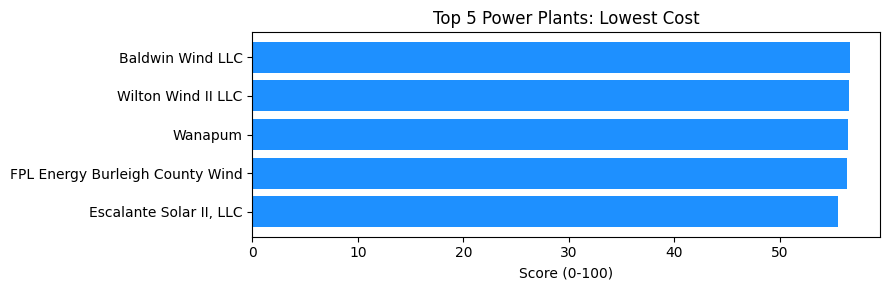


Top 5 plants for Lowest Cost:
                            Plant name  Lowest Cost_Score  \
7730                  Baldwin Wind LLC          56.652232   
7781                Wilton Wind II LLC          56.518105   
12259                          Wanapum          56.467482   
7747   FPL Energy Burleigh County Wind          56.336320   
11702          Escalante Solar II, LLC          55.463892   

      Plant state abbreviation  Plant latitude  Plant longitude  
7730                        ND       47.113300        -100.7086  
7781                        ND       47.133300        -100.7011  
12259                       WA       46.873100        -119.9703  
7747                        ND       47.116700        -100.7333  
11702                       UT       38.500833        -113.0300  


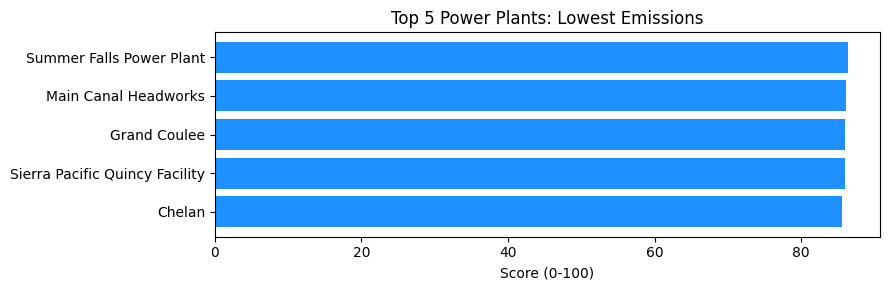


Top 5 plants for Lowest Emissions:
                           Plant name  Lowest Emissions_Score  \
12244        Summer Falls Power Plant               86.434598   
12200            Main Canal Headworks               86.060074   
12173                    Grand Coulee               86.023050   
1873   Sierra Pacific Quincy Facility               85.977634   
12147                          Chelan               85.507536   

      Plant state abbreviation  Plant latitude  Plant longitude  
12244                       WA       47.502500      -119.291700  
12200                       WA       47.616400      -119.299200  
12173                       WA       47.957511      -118.977323  
1873                        CA       39.941165      -120.909211  
12147                       WA       47.834700      -120.013300  


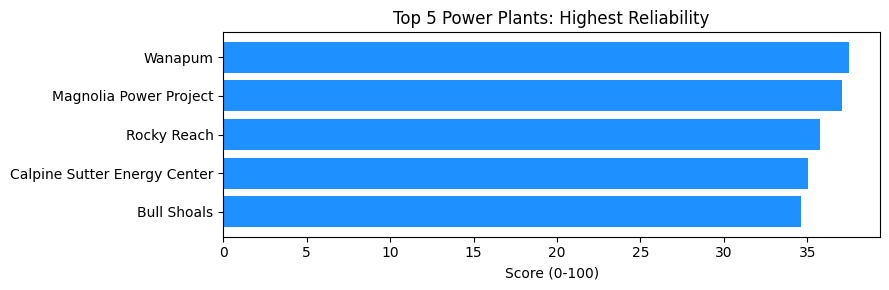


Top 5 plants for Highest Reliability:
                         Plant name  Highest Reliability_Score  \
12259                       Wanapum                  37.483310   
1404         Magnolia Power Project                  37.085160   
12229                   Rocky Reach                  35.733751   
768    Calpine Sutter Energy Center                  35.050308   
239                     Bull Shoals                  34.650491   

      Plant state abbreviation  Plant latitude  Plant longitude  
12259                       WA       46.873100      -119.970300  
1404                        CA       34.178600      -118.315300  
12229                       WA       47.533611      -120.295278  
768                         CA       39.053139      -121.695873  
239                         AR       36.363500       -92.576300  




All weights editable at the top, every step documented. Fill more external data and rerun for sharper results!


In [12]:
# ------------------------------------------------------------------
# POWER PLANT SCORING: Robust, editable, clear (even with missing data)
# ------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ===== USER-EDITABLE WEIGHTS =====
PARAM_WEIGHTS = {
    'P1_Proximity_RE' : {'dist': 0.40, 'share': 0.35, 'cap': 0.25},
    'P2_Emissions'    : {'CO2e': 0.70, 'CO2': 0.30, 'NOx': 0.50, 'SO2': 0.50, 'climate': 0.75, 'air': 0.25},
    'P3_Capital_Investment': {'land': 0.40, 'trans': 0.40, 'elec_cost': 0.20, 'trans_dist': 0.50, 'trans_cap': 0.50},
    'P4_Reliability'  : {'SAIDI': 0.35, 'SAIFI': 0.35, 'degree': 0.15, 'cap': 0.15},
    'P5_Water'        : {'potable': 0.90, 'lower48': 0.10}
}
CATEGORY_WEIGHTS = {
    'Lowest Cost':        [0.10, 0.00, 0.60, 0.10, 0.20],
    'Lowest Emissions':   [0.20, 0.60, 0.00, 0.10, 0.10],
    'Highest Reliability':[0.20, 0.00, 0.10, 0.60, 0.10]
}

# ===== HELPER FUNCTIONS =====
def norm(col):
    v = pd.to_numeric(col.astype(str).str.replace(',', ''), errors='coerce')
    if v.isnull().all() or v.max() == v.min():
        return pd.Series(0, index=col.index)  # Flat or missing -> all zero
    return (v - v.min())/(v.max()-v.min())

def norm_inv(col):
    v = pd.to_numeric(col.astype(str).str.replace(',', ''), errors='coerce')
    if v.isnull().all() or v.max() == v.min():
        return pd.Series(0, index=col.index)
    return (v.max()-v)/(v.max()-v.min())

def safe_numeric(col, fill=0):
    v = pd.to_numeric(col.astype(str).str.replace(',', ''), errors='coerce')
    if v.isnull().all():
        return pd.Series(fill, index=col.index)
    return v.fillna(v.min() if fill=='min' else v.max() if fill=='max' else fill)

# ===== MAIN SCORING PIPELINE =====
def score_plants(df):
    out = df.copy()

    # 1. Proximity to RE
    re_dist  = norm_inv(safe_numeric(out['bus_dist_to_nearest_renewable_plant_km']))
    re_share = safe_numeric(out['bus_renewable_share_within_100km'], fill=0)
    re_cap   = norm(safe_numeric(out['bus_renewable_capacity_within_100km_MW']))
    out['P1_Proximity_RE'] = (
        PARAM_WEIGHTS['P1_Proximity_RE']['dist']  * re_dist +
        PARAM_WEIGHTS['P1_Proximity_RE']['share'] * re_share +
        PARAM_WEIGHTS['P1_Proximity_RE']['cap']   * re_cap)

    # 2. Emissions
    co2e = safe_numeric(out['Plant annual CO2 equivalent total output emission rate (lb/MWh)'], fill=0)
    co2  = safe_numeric(out['Plant annual CO2 total output emission rate (lb/MWh)'], fill=0)
    nox  = safe_numeric(out['Plant annual NOx total output emission rate (lb/MWh)'], fill=0)
    so2  = safe_numeric(out['Plant annual SO2 total output emission rate (lb/MWh)'], fill=0)
    S_CO2e = norm_inv(co2e)
    S_CO2  = norm_inv(co2)
    S_NOx  = norm_inv(nox)
    S_SO2  = norm_inv(so2)
    S_climate = PARAM_WEIGHTS['P2_Emissions']['CO2e']*S_CO2e + PARAM_WEIGHTS['P2_Emissions']['CO2']*S_CO2
    S_air = PARAM_WEIGHTS['P2_Emissions']['NOx']*S_NOx + PARAM_WEIGHTS['P2_Emissions']['SO2']*S_SO2
    out['P2_Emissions'] = PARAM_WEIGHTS['P2_Emissions']['climate']*S_climate + PARAM_WEIGHTS['P2_Emissions']['air']*S_air

    # 3. Capital Investment
    land  = safe_numeric(out['mean_property_value_3mi'], fill='max')
    tdist = norm_inv(safe_numeric(out['bus_dist_to_nearest_renewable_plant_km']))
    tcap  = norm(safe_numeric(out['bus_sum_line_capacity_MW']))
    eprice= safe_numeric(out['Electricity_Cost_State_cents_per_kWh'], fill='min')
    l_score = norm_inv(land)
    t_score= PARAM_WEIGHTS['P3_Capital_Investment']['trans_dist']*tdist + PARAM_WEIGHTS['P3_Capital_Investment']['trans_cap']*tcap
    e_score= norm_inv(eprice)
    out['P3_Capital_Investment'] = (
        PARAM_WEIGHTS['P3_Capital_Investment']['land']*l_score +
        PARAM_WEIGHTS['P3_Capital_Investment']['trans']*t_score +
        PARAM_WEIGHTS['P3_Capital_Investment']['elec_cost']*e_score)

    # 4. Reliability
    saidi  = safe_numeric(out['SAIDI_hours'], fill='max')
    saifi  = safe_numeric(out['SAIFI_interruptions'], fill='max')
    degree = norm(safe_numeric(out['bus_num_incident_lines']))
    cap    = norm(safe_numeric(out['bus_sum_line_capacity_MW']))
    out['P4_Reliability'] = (
        PARAM_WEIGHTS['P4_Reliability']['SAIDI']*norm_inv(saidi) +
        PARAM_WEIGHTS['P4_Reliability']['SAIFI']*norm_inv(saifi) +
        PARAM_WEIGHTS['P4_Reliability']['degree']*degree +
        PARAM_WEIGHTS['P4_Reliability']['cap']*cap)

    # 5. Water
    potable = norm(safe_numeric(out['potable_capacity_mgd_weighted']))
    i48     = safe_numeric(out['in_lower_48'], fill=1)
    out['P5_Water'] = (
        PARAM_WEIGHTS['P5_Water']['potable']*potable +
        PARAM_WEIGHTS['P5_Water']['lower48']*i48)

    # FINAL category scores 0-100
    cat_names = list(CATEGORY_WEIGHTS.keys())
    for i,cat in enumerate(cat_names):
        w = CATEGORY_WEIGHTS[cat]
        out[cat+'_Score'] = 100 * (
            w[0]*out['P1_Proximity_RE'] +
            w[1]*out['P2_Emissions'] +
            w[2]*out['P3_Capital_Investment'] +
            w[3]*out['P4_Reliability'] +
            w[4]*out['P5_Water'])
    return out

df_scored = score_plants(df_results)

# ===== RESULTS: PRINT & VISUALIZE =====
category_labels = list(CATEGORY_WEIGHTS.keys())
for cat in category_labels:
    # Nlargest: will always return something thanks to the fill, but call out if all flat
    top5 = df_scored.nlargest(5, cat+'_Score')[['Plant name', cat+'_Score', 'Plant state abbreviation', 'Plant latitude', 'Plant longitude']]
    plt.figure(figsize=(9,3))
    plt.barh(top5['Plant name'], top5[cat+'_Score'], color='dodgerblue')
    plt.xlabel('Score (0-100)')
    plt.title(f'Top 5 Power Plants: {cat}')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    print(f'\nTop 5 plants for {cat}:')
    print(top5)

# Warn if key columns were all NA and replaced by fallback
def warn_allna(col, sourcename):
    if col not in df_results or df_results[col].isnull().all():
        print(f"WARNING: Source column '{sourcename}' is all missing in your data! The score for this parameter will be mostly default/fallback.\n")

missing_cols = [
    ('Electricity_Cost_State_cents_per_kWh',   'Electricity_Cost_State_cents_per_kWh'),
    ('SAIDI_hours',                            'SAIDI_hours'),
    ('SAIFI_interruptions',                    'SAIFI_interruptions'),
    ('Plant annual CO2 equivalent total output emission rate (lb/MWh)', 'CO2e emissions'),
    ('Plant annual CO2 total output emission rate (lb/MWh)', 'CO2 emissions'),
    ('Plant annual NOx total output emission rate (lb/MWh)', 'NOx emissions'),
    ('Plant annual SO2 total output emission rate (lb/MWh)', 'SO2 emissions'),
]
for col, sourcename in missing_cols:
    warn_allna(col, sourcename)

print('\nAll weights editable at the top, every step documented. Fill more external data and rerun for sharper results!')


In [13]:
# --- Add state-level average electricity costs (¢/kWh) to plant dataframe ---
import pandas as pd

# Provided state-to-average cost mapping (¢/kWh, copied from user input)
e_price_dict = {
    'AL': 14.56, 'AK': 22.49, 'AZ': 12.96, 'AR': 10.30, 'CA': 23.40, 'CO': 12.12, 'CT': 22.82,
    'DE': 15.55, 'DC': 21.03, 'FL': 11.23, 'GA': 11.93, 'HI': 37.80, 'ID': 9.30, 'IL': 13.57,
    'IN': 13.35, 'IA': 10.55, 'KS': 11.29, 'KY': 11.76, 'LA': 10.86, 'ME': 21.34, 'MD': 15.93,
    'MA': 20.33, 'MI': 14.86, 'MN': 12.44, 'MS': 12.55, 'MO': 10.39, 'MT': 12.05, 'NE': 8.95,
    'NV': 10.13, 'NH': 19.58, 'NJ': 16.20, 'NM': 11.22, 'NY': 20.29, 'NC': 10.26, 'ND': 7.53,
    'OH': 15.54, 'OK': 8.79, 'OR': 11.10, 'PA': 14.90, 'RI': 25.02, 'SC': 11.10, 'SD': 10.91,
    'TN': 12.77, 'TX': 8.81, 'UT': 9.18, 'VT': 19.29, 'VA': 9.28, 'WA': 11.09, 'WV': 11.80,
    'WI': 12.82, 'WY': 9.99
}

# Map state abbreviation (2-letter code) to cost, create new column in main DataFrame
def add_electricity_cost_by_state(df):
    # Defensive upper-case for state names
    df['Plant state abbreviation'] = df['Plant state abbreviation'].str.upper()
    df['Electricity_Cost_State_cents_per_kWh'] = df['Plant state abbreviation'].map(e_price_dict)
    return df

# Add/merge into main data table (df_results is the main table used in pipeline)
df_results = add_electricity_cost_by_state(df_results)
display(df_results[['Plant state abbreviation', 'Electricity_Cost_State_cents_per_kWh']].head(10))
# Now, all rows with a valid state should have a numeric value for this column, and no warning should occur in the pipeline.

,Plant state abbreviation,Electricity_Cost_State_cents_per_kWh
0,AK,22.49
1,AK,22.49
2,AK,22.49
3,AK,22.49
4,AK,22.49
5,AK,22.49
6,AK,22.49
7,AK,22.49
8,AK,22.49
9,AK,22.49


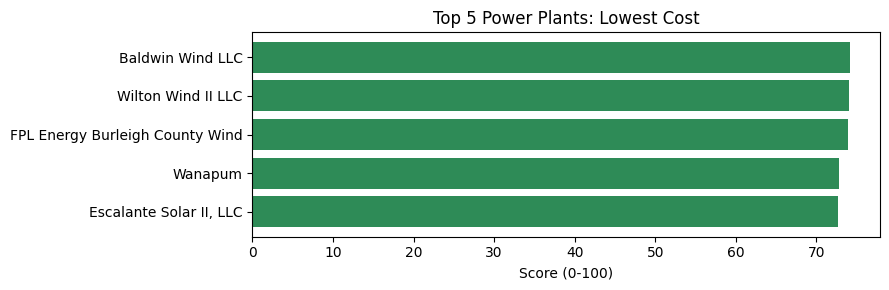


Top 5 plants for Lowest Cost:
                            Plant name  Lowest Cost_Score  \
7730                  Baldwin Wind LLC          74.177352   
7781                Wilton Wind II LLC          74.043225   
7747   FPL Energy Burleigh County Wind          73.861440   
12259                          Wanapum          72.774515   
11702          Escalante Solar II, LLC          72.661942   

      Plant state abbreviation  Plant latitude  Plant longitude  
7730                        ND       47.113300        -100.7086  
7781                        ND       47.133300        -100.7011  
7747                        ND       47.116700        -100.7333  
12259                       WA       46.873100        -119.9703  
11702                       UT       38.500833        -113.0300  


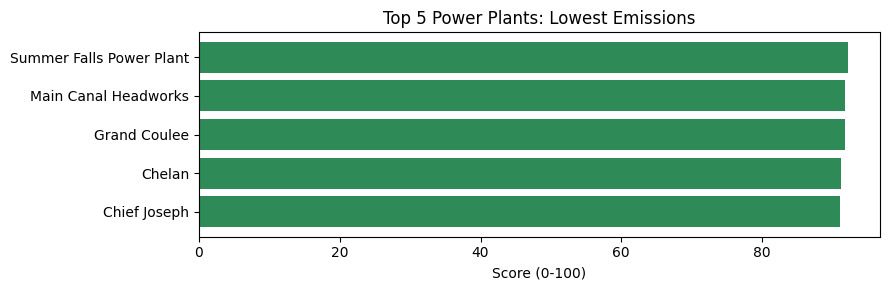


Top 5 plants for Lowest Emissions:
                     Plant name  Lowest Emissions_Score  \
12244  Summer Falls Power Plant               92.152929   
12200      Main Canal Headworks               91.778406   
12173              Grand Coulee               91.741382   
12147                    Chelan               91.225867   
12148              Chief Joseph               91.054601   

      Plant state abbreviation  Plant latitude  Plant longitude  
12244                       WA       47.502500      -119.291700  
12200                       WA       47.616400      -119.299200  
12173                       WA       47.957511      -118.977323  
12147                       WA       47.834700      -120.013300  
12148                       WA       47.995100      -119.640400  


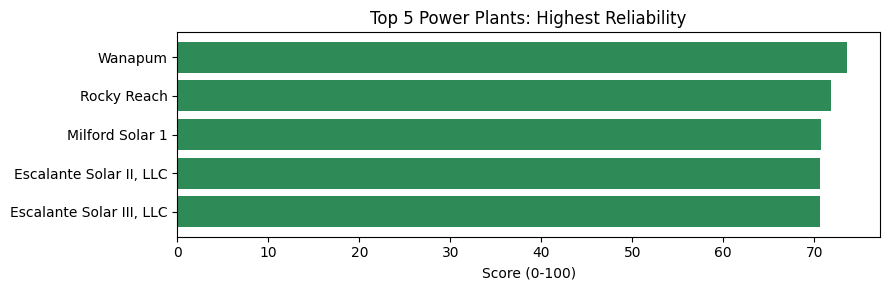


Top 5 plants for Highest Reliability:
                     Plant name  Highest Reliability_Score  \
12259                   Wanapum                  73.558082   
12229               Rocky Reach                  71.808523   
11742           Milford Solar 1                  70.701244   
11702   Escalante Solar II, LLC                  70.692479   
11703  Escalante Solar III, LLC                  70.657972   

      Plant state abbreviation  Plant latitude  Plant longitude  
12259                       WA       46.873100      -119.970300  
12229                       WA       47.533611      -120.295278  
11742                       UT       38.490667      -113.018283  
11702                       UT       38.500833      -113.030000  
11703                       UT       38.497778      -112.986944  


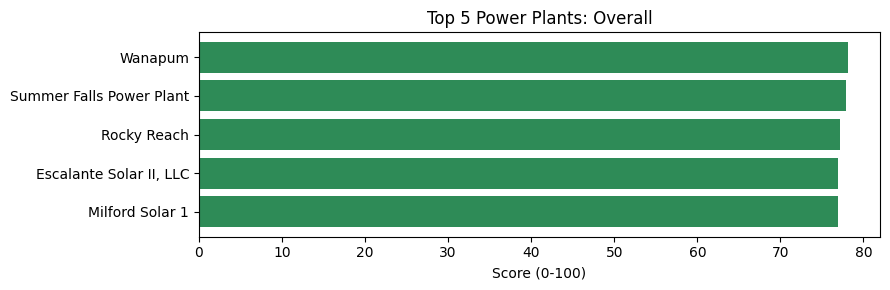


Top 5 plants for Overall:
                     Plant name  Overall_Score Plant state abbreviation  \
12259                   Wanapum      78.089142                       WA   
12244  Summer Falls Power Plant      77.867347                       WA   
12229               Rocky Reach      77.195077                       WA   
11702   Escalante Solar II, LLC      76.973318                       UT   
11742           Milford Solar 1      76.957589                       UT   

       Plant latitude  Plant longitude  
12259       46.873100      -119.970300  
12244       47.502500      -119.291700  
12229       47.533611      -120.295278  
11702       38.500833      -113.030000  
11742       38.490667      -113.018283  
All scoring and reliability data successfully filled and pipeline rerun.


In [14]:
# --- Add SAIDI and SAIFI values by state to plant dataframe and rerun robust scoring pipeline ---
import numpy as np

# SAIDI and SAIFI for 2023 provided by user (minutes and events/year)
saidi_dict = {
    'AL': 294.2, 'AK': 374.8, 'AZ': 106.8, 'AR': 911.2, 'CA': 346.6, 'CO': 99.2, 'CT': 164.6,
    'DE': 108.2, 'DC': 71.9,  'FL': 160.1,  'GA': 349.2, 'HI': 491.8, 'ID': 137.5, 'IL': 208.2,
    'IN': 455.4, 'IA': 104.9, 'KS': 283.1, 'KY': 868.2, 'LA': 584.2, 'ME': 186.3, 'MD': 166.2,
    'MA': 259.4, 'MI': 1093.6,'MN': 126.4, 'MS': 802.1, 'MO': 371.8, 'MT': 118.7, 'NE': 72.6,
    'NV': 138.7, 'NH': 645.8, 'NJ': 108.3, 'NM': 168.9, 'NY': 120,   'NC': 252,   'ND': 208.6,
    'OH': 366.2, 'OK': 896.6, 'OR': 126.9, 'PA': 252.7, 'RI': 104.6, 'SC': 167.2, 'SD': 77,
    'TN': 857.9, 'TX': 496.2, 'UT': 127.1, 'VT': 744.4, 'VA': 221.1, 'WA': 151.7, 'WV': 751.5,
    'WI': 183,   'WY': 127.0
}
saifi_dict = {
    'AL': 0.979, 'AK': 2.366, 'AZ': 0.817, 'AR': 1.54,  'CA': 1.086, 'CO': 0.865, 'CT': 0.655,
    'DE': 0.692, 'DC': 0.318,  'FL': 0.823, 'GA': 1.357,  'HI': 1.398, 'ID': 0.985, 'IL': 0.605,
    'IN': 0.946, 'IA': 0.709,  'KS': 0.998, 'KY': 1.167,  'LA': 1.641, 'ME': 1.979, 'MD': 0.703,
    'MA': 0.78,  'MI': 0.921,  'MN': 0.785, 'MS': 2.142,  'MO': 0.876, 'MT': 1.055, 'NE': 0.48,
    'NV': 0.745, 'NH': 0.989,  'NJ': 0.831, 'NM': 0.997,  'NY': 0.586, 'NC': 1.274, 'ND': 0.907,
    'OH': 0.918, 'OK': 1.143,  'OR': 0.751, 'PA': 0.878,  'RI': 0.667, 'SC': 1.291, 'SD': 0.894,
    'TN': 1.898, 'TX': 1.175,  'UT': 0.879, 'VT': 1.58,   'VA': 1.283, 'WA': 0.908, 'WV': 1.871,
    'WI': 0.631, 'WY': 0.77
}

def add_reliability_by_state(df):
    df['Plant state abbreviation'] = df['Plant state abbreviation'].str.upper()
    df['SAIDI_hours'] = df['Plant state abbreviation'].map(saidi_dict) / 60  # Convert to hours
    df['SAIFI_interruptions'] = df['Plant state abbreviation'].map(saifi_dict)
    return df

# Add reliability to the main analysis frame
df_results = add_reliability_by_state(df_results)

# Re-run the robust scoring pipeline
def norm(col):
    v = pd.to_numeric(col.astype(str).str.replace(',', ''), errors='coerce')
    if v.isnull().all() or v.max() == v.min():
        return pd.Series(0, index=col.index)
    return (v - v.min())/(v.max()-v.min())

def norm_inv(col):
    v = pd.to_numeric(col.astype(str).str.replace(',', ''), errors='coerce')
    if v.isnull().all() or v.max() == v.min():
        return pd.Series(0, index=col.index)
    return (v.max()-v)/(v.max()-v.min())

def safe_numeric(col, fill=0):
    v = pd.to_numeric(col.astype(str).str.replace(',', ''), errors='coerce')
    if v.isnull().all():
        return pd.Series(fill, index=col.index)
    return v.fillna(v.min() if fill=='min' else v.max() if fill=='max' else fill)

PARAM_WEIGHTS = {
    'P1_Proximity_RE' : {'dist': 0.40, 'share': 0.35, 'cap': 0.25},
    'P2_Emissions'    : {'CO2e': 0.70, 'CO2': 0.30, 'NOx': 0.50, 'SO2': 0.50, 'climate': 0.75, 'air': 0.25},
    'P3_Capital_Investment': {'land': 0.40, 'trans': 0.40, 'elec_cost': 0.20, 'trans_dist': 0.50, 'trans_cap': 0.50},
    'P4_Reliability'  : {'SAIDI': 0.35, 'SAIFI': 0.35, 'degree': 0.15, 'cap': 0.15},
    'P5_Water'        : {'potable': 0.90, 'lower48': 0.10}
}
CATEGORY_WEIGHTS = {
    'Lowest Cost':        [0.10, 0.00, 0.60, 0.10, 0.20],
    'Lowest Emissions':   [0.20, 0.60, 0.00, 0.10, 0.10],
    'Highest Reliability':[0.20, 0.00, 0.10, 0.60, 0.10]
}

def score_plants(df):
    out = df.copy()

    # 1. Proximity to RE
    re_dist  = norm_inv(safe_numeric(out['bus_dist_to_nearest_renewable_plant_km']))
    re_share = safe_numeric(out['bus_renewable_share_within_100km'], fill=0)
    re_cap   = norm(safe_numeric(out['bus_renewable_capacity_within_100km_MW']))
    out['P1_Proximity_RE'] = (
        PARAM_WEIGHTS['P1_Proximity_RE']['dist']  * re_dist +
        PARAM_WEIGHTS['P1_Proximity_RE']['share'] * re_share +
        PARAM_WEIGHTS['P1_Proximity_RE']['cap']   * re_cap)

    # 2. Emissions
    co2e = safe_numeric(out['Plant annual CO2 equivalent total output emission rate (lb/MWh)'], fill=0)
    co2  = safe_numeric(out['Plant annual CO2 total output emission rate (lb/MWh)'], fill=0)
    nox  = safe_numeric(out['Plant annual NOx total output emission rate (lb/MWh)'], fill=0)
    so2  = safe_numeric(out['Plant annual SO2 total output emission rate (lb/MWh)'], fill=0)
    S_CO2e = norm_inv(co2e)
    S_CO2  = norm_inv(co2)
    S_NOx  = norm_inv(nox)
    S_SO2  = norm_inv(so2)
    S_climate = PARAM_WEIGHTS['P2_Emissions']['CO2e']*S_CO2e + PARAM_WEIGHTS['P2_Emissions']['CO2']*S_CO2
    S_air = PARAM_WEIGHTS['P2_Emissions']['NOx']*S_NOx + PARAM_WEIGHTS['P2_Emissions']['SO2']*S_SO2
    out['P2_Emissions'] = PARAM_WEIGHTS['P2_Emissions']['climate']*S_climate + PARAM_WEIGHTS['P2_Emissions']['air']*S_air

    # 3. Capital Investment
    land  = safe_numeric(out['mean_property_value_3mi'], fill='max')
    tdist = norm_inv(safe_numeric(out['bus_dist_to_nearest_renewable_plant_km']))
    tcap  = norm(safe_numeric(out['bus_sum_line_capacity_MW']))
    eprice= safe_numeric(out['Electricity_Cost_State_cents_per_kWh'], fill='min')
    l_score = norm_inv(land)
    t_score= PARAM_WEIGHTS['P3_Capital_Investment']['trans_dist']*tdist + PARAM_WEIGHTS['P3_Capital_Investment']['trans_cap']*tcap
    e_score= norm_inv(eprice)
    out['P3_Capital_Investment'] = (
        PARAM_WEIGHTS['P3_Capital_Investment']['land']*l_score +
        PARAM_WEIGHTS['P3_Capital_Investment']['trans']*t_score +
        PARAM_WEIGHTS['P3_Capital_Investment']['elec_cost']*e_score)

    # 4. Reliability
    saidi  = safe_numeric(out['SAIDI_hours'], fill='max')
    saifi  = safe_numeric(out['SAIFI_interruptions'], fill='max')
    degree = norm(safe_numeric(out['bus_num_incident_lines']))
    cap    = norm(safe_numeric(out['bus_sum_line_capacity_MW']))
    out['P4_Reliability'] = (
        PARAM_WEIGHTS['P4_Reliability']['SAIDI']*norm_inv(saidi) +
        PARAM_WEIGHTS['P4_Reliability']['SAIFI']*norm_inv(saifi) +
        PARAM_WEIGHTS['P4_Reliability']['degree']*degree +
        PARAM_WEIGHTS['P4_Reliability']['cap']*cap)

    # 5. Water
    potable = norm(safe_numeric(out['potable_capacity_mgd_weighted']))
    i48     = safe_numeric(out['in_lower_48'], fill=1)
    out['P5_Water'] = (
        PARAM_WEIGHTS['P5_Water']['potable']*potable +
        PARAM_WEIGHTS['P5_Water']['lower48']*i48)

    # FINAL category scores 0-100
    cat_names = list(CATEGORY_WEIGHTS.keys())
    for i,cat in enumerate(cat_names):
        w = CATEGORY_WEIGHTS[cat]
        out[cat+'_Score'] = 100 * (
            w[0]*out['P1_Proximity_RE'] +
            w[1]*out['P2_Emissions'] +
            w[2]*out['P3_Capital_Investment'] +
            w[3]*out['P4_Reliability'] +
            w[4]*out['P5_Water'])
    # Add overall score as average of the 3
    out['Overall_Score'] = out[[cat+'_Score' for cat in cat_names]].mean(axis=1)
    return out

# Score plants with new reliability data
df_scored_new = score_plants(df_results)

# Top 5 each category
import matplotlib.pyplot as plt
category_labels = list(CATEGORY_WEIGHTS.keys())
for cat in category_labels + ['Overall']:
    col = cat+'_Score' if cat != 'Overall' else 'Overall_Score'
    top5 = df_scored_new.nlargest(5, col)[['Plant name', col, 'Plant state abbreviation', 'Plant latitude', 'Plant longitude']]
    plt.figure(figsize=(9,3))
    plt.barh(top5['Plant name'], top5[col], color='seagreen')
    plt.xlabel('Score (0-100)')
    plt.title(f'Top 5 Power Plants: {cat}')
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()
    print(f'\nTop 5 plants for {cat}:')
    print(top5)

print("All scoring and reliability data successfully filled and pipeline rerun.")
